# PackNet

In [13]:
import warnings
warnings.filterwarnings("ignore")

import os, math, time, json, random
from pathlib import Path
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.models as tvm
import torchvision.transforms as T

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE)

Device: cuda


In [14]:
# Configurations 
SEED = 67
N_TASKS = 10
CLASSES_PER_TASK = 10
ORDER_ID = 0

IMAGE_SIZE = 32
BATCH_SIZE = 128
NUM_WORKERS = 2

EPOCHS_PER_TASK = 30
LR = 0.01
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
RETRAIN_EPOCHS = 10
RETRAIN_LR = 0.001

PRETRAINED = True
GN_GROUPS = 32
PRUNE_PERC = 0.5

DATA_DIR = next(Path("/kaggle/input").rglob("task_order.json")).parent   # mounted DL_Dataset
PLOT_DIR = Path("/kaggle/working/Plots")
PLOT_DIR.mkdir(parents=True, exist_ok=True)


def set_seed(seed=SEED):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

In [15]:
# Data Loading

CIFAR100_MEAN = (0.5071, 0.4865, 0.4409)
CIFAR100_STD  = (0.2673, 0.2564, 0.2762)

eval_tf = [T.ToTensor(), T.Normalize(CIFAR100_MEAN, CIFAR100_STD)]
train_tf = [T.RandomCrop(IMAGE_SIZE, padding=4), T.RandomHorizontalFlip()] + eval_tf
if IMAGE_SIZE != 32:
    train_tf, eval_tf = [T.Resize(IMAGE_SIZE)] + train_tf, [T.Resize(IMAGE_SIZE)] + eval_tf
transform_train, transform_eval = T.Compose(train_tf), T.Compose(eval_tf)

with open(DATA_DIR / "task_order.json") as f:
    meta = json.load(f)
ORDER = meta["task_orders"][ORDER_ID]

class TaskDataset(Dataset):
    def __init__(self, path, transform):
        data = np.load(path)
        self.images, self.labels, self.transform = data["images"], data["labels_local"], transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.transform(Image.fromarray(self.images[i])), int(self.labels[i])

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)

generator = torch.Generator()
generator.manual_seed(SEED)

def get_task_loaders(task_idx):
    """task_idx is the 0-indexed task ID; returns {'train', 'valid', 'test'} loaders."""
    loaders = {}
    for split in ("train", "valid", "test"):
        ds = TaskDataset(DATA_DIR / f"task-{task_idx + 1}" / split / "data.npz", transform_train if split == "train" else transform_eval)
        loaders[split] = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=(split == "train"),num_workers=NUM_WORKERS,
                                    pin_memory=True, worker_init_fn=seed_worker, generator=generator)
    return loaders

loaders = [get_task_loaders(ORDER[p]) for p in range(N_TASKS)]
print(f"Order {ORDER_ID} : {ORDER}")

Order 0 : [3, 8, 1, 4, 9, 0, 2, 6, 7, 5]


In [16]:
# GroupNorm Helpers 
def groups_for(num_channels, preferred=GN_GROUPS):
    if num_channels % preferred == 0:
        return preferred
    return max(math.gcd(preferred, num_channels), 1)

def bn_to_gn(module):
    for name, child in module.named_children():
        if isinstance(child, nn.BatchNorm2d):
            setattr(module, name, nn.GroupNorm(groups_for(child.num_features), child.num_features))
        else:
            bn_to_gn(child)
    return module

def prunable_parameters(model):
    """Backbone conv weights only — GroupNorm affine params, biases and the per-task heads are excluded."""
    gn_modules = {n for n, m in model.named_modules() if isinstance(m, nn.GroupNorm)}
    for name, p in model.named_parameters():
        parent = name.rsplit(".", 1)[0]
        if name.endswith(".weight") and parent not in gn_modules and not name.startswith("head."):
            yield name, p

# Metrics
def accuracy(logits, y):
    return (logits.argmax(dim=1) == y).float().mean().item()

def empty_accuracy_matrix(n_tasks):
    return np.full((n_tasks, n_tasks), np.nan, dtype=float)

def set_accuracy(R, after_task, eval_task, acc):
    R[after_task, eval_task] = acc

def forgetting(R):
    n = R.shape[0]
    per_task = np.array([R[i, i] - R[n - 1, i] for i in range(n - 1)], dtype=float)
    return {"per_task": per_task.tolist(), "average": float(np.nanmean(per_task)) if per_task.size else 0.0}

def final_average_accuracy(R):
    return float(np.nanmean(R[R.shape[0] - 1]))

def capacity_stats(masks):
    total, allocated, per_task = 0, 0, {}
    for m in masks.values():
        m = m.cpu().numpy()
        total += m.size
        allocated += int((m > 0).sum())
        for t in np.unique(m):
            t = int(t)
            if t > 0:
                per_task[t] = per_task.get(t, 0) + int((m == t).sum())
    free = total - allocated
    return {
        "total_parameters": total,
        "active_parameter_count": allocated,
        "allocated_fraction": allocated / total if total else 0.0,
        "free_fraction": free / total if total else 0.0,
        "per_task_parameters": per_task,
    }

## Model definition

ResNet-50 (GroupNorm) backbone + one shared head, plus the PackNet mask manager.

In [17]:
def build_backbone(pretrained=PRETRAINED):
    weights = tvm.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
    model = tvm.resnet50(weights=weights)
    model = bn_to_gn(model)
    for m in model.modules():
        if isinstance(m, tvm.resnet.Bottleneck):
            nn.init.zeros_(m.bn3.weight)   # zero-init residual: without it the GN-swapped ResNet-50 diverges
    feature_dim = model.fc.in_features
    model.fc = nn.Identity()
    model.feature_dim = feature_dim
    return model

class PackNetResNet(nn.Module):
    """ResNet-50 (GroupNorm) backbone + a classification head. The head is re-initialised for
    every task and its trained state is stored per task (PackNet only masks the backbone)."""

    def __init__(self, num_classes=CLASSES_PER_TASK):
        super().__init__()
        self.backbone = build_backbone()
        self.head = nn.Linear(self.backbone.feature_dim, num_classes)

    def forward(self, x):
        return self.head(self.backbone(x))

class PackNet:
    """Iterative-pruning mask manager (Mallya & Lazebnik, 2018).
    mask[name] == 0  -> free, still trainable
    mask[name] == t  -> owned by task t, frozen from then on
    Non-masked parameters: GroupNorm affine is trained in task 1 then frozen;
    each task gets its own head, stored here and swapped in at evaluation."""

    def __init__(self, model, prune_perc=PRUNE_PERC):
        self.model = model
        self.prune_perc = prune_perc
        self.masks = {name: torch.zeros_like(p, dtype=torch.uint8)
                      for name, p in prunable_parameters(model)}
        self.heads = {}

    def mask_gradients(self, owner):
        """Train only the weights whose mask == owner (0 = free weights, t = current task's
        kept weights during retraining). Weight decay is added here, on those weights only,
        so frozen weights never decay."""
        for name, p in prunable_parameters(self.model):
            if p.grad is not None:
                p.grad.add_(p.data, alpha=WEIGHT_DECAY)
                p.grad.masked_fill_(self.masks[name] != owner, 0)

    def prune(self, task_id):
        """Keep the top (1 - prune_perc) free weights by magnitude for `task_id`;
        zero out and free the rest for future tasks."""
        for name, p in prunable_parameters(self.model):
            mask = self.masks[name]
            free = mask == 0
            n_free = int(free.sum())
            if n_free == 0:
                continue
            k = max(int((1 - self.prune_perc) * n_free), 1)
            scores = p.data.abs().masked_fill(~free, -1.0).flatten()
            keep = torch.zeros_like(scores, dtype=torch.bool)
            keep[torch.topk(scores, k).indices] = True
            keep = keep.view_as(free)
            mask[keep] = task_id
            p.data[free & ~keep] = 0.0

    def freeze_norms(self):
        for m in self.model.modules():
            if isinstance(m, nn.GroupNorm):
                for p in m.parameters():
                    p.requires_grad_(False)

    def new_head(self):
        self.model.head.reset_parameters()

    def save_head(self, task_id):
        self.heads[task_id] = deepcopy(self.model.head.state_dict())

    def apply_eval_mask(self, task_id):
        """Zero every weight not owned by tasks 1..task_id and load task_id's head;
        returns the originals so the caller can put them back with `restore`."""
        originals = {"head": deepcopy(self.model.head.state_dict())}
        for name, p in prunable_parameters(self.model):
            mask = self.masks[name]
            active = (mask > 0) & (mask <= task_id)
            originals[name] = p.data.clone()
            p.data[~active] = 0.0
        self.model.head.load_state_dict(self.heads[task_id])
        return originals

    def restore(self, originals):
        for name, p in prunable_parameters(self.model):
            p.data.copy_(originals[name])
        self.model.head.load_state_dict(originals["head"])

## Model summary

In [18]:
model = PackNetResNet().to(DEVICE)
packnet = PackNet(model)

n_total = sum(p.numel() for p in model.parameters())
n_prunable = sum(p.numel() for _, p in prunable_parameters(model))

print(f"Total Parameters    : {n_total:,}")
print(f"Prunable Parameters : {n_prunable:,}  ({n_prunable / n_total:.1%} of total)")
print(f"prunable Tensors    : {len(packnet.masks)}")

Total Parameters    : 23,528,522
Prunable Parameters : 23,454,912  (99.7% of total)
prunable Tensors    : 53


## Training Definition

In [25]:
criterion = nn.CrossEntropyLoss()

def run_epoch(loader, optimizer=None, scaler=None, train=True, owner=0):
    model.train() if train else model.eval()
    total_loss, total_acc, n = 0.0, 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                packnet.mask_gradients(owner)
                scaler.step(optimizer)
                scaler.update()
        bs = y.size(0)
        total_loss += loss.item() * bs
        total_acc += accuracy(out, y) * bs
        n += bs
    return total_loss / n, total_acc / n

def fit(task_loaders, epochs, lr, owner, select_best):
    """Train the weights with mask == owner for `epochs`. If select_best, the best-validation
    epoch is kept in memory and reloaded at the end."""
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=lr, momentum=MOMENTUM, weight_decay=0)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history = {'epoch': [], 'train_loss': [], 'validation_loss': [], 'train_accuracy': [], 'validation_accuracy': [], 'lr': []}
    best_val_acc, best_epoch, best_state = -1.0, 0, None

    hdr = (f"{'Epoch':>6}  {'T-Loss':>8}  {'V-Loss':>8} {'T-Acc':>8}  {'V-Acc':>8}{'LR':>10}     {'Time':>7}")
    print(hdr)
    print('─' * (len(hdr)+2))

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        cur_lr = optimizer.param_groups[0]["lr"]
        tr_loss, tr_acc = run_epoch(task_loaders["train"], optimizer, scaler, train=True, owner=owner)
        va_loss, va_acc = run_epoch(task_loaders["valid"], train=False)
        scheduler.step()

        for k, v in zip(history, [epoch, tr_loss, va_loss, tr_acc, va_acc, cur_lr]):
            history[k].append(v)

        saved_flag = ''
        if select_best and va_acc > best_val_acc:
            best_val_acc, best_epoch, best_state = va_acc, epoch, deepcopy(model.state_dict())
            saved_flag = ' ★'

        print(f'{epoch:>6}  {tr_loss:>8.4f}  {va_loss:>8.4f}  '
              f'{tr_acc:>8.4f}  {va_acc:>8.4f}  {cur_lr:>10.2e}  {time.time() - t0:>6.1f}s{saved_flag}')

    print('─' * len(hdr))
    if select_best:
        model.load_state_dict(best_state)
        print(f'best val acc: {best_val_acc:.4f} @ epoch {best_epoch} (reloaded)')
    return history

## Main Training Loop

In [ ]:
R = empty_accuracy_matrix(N_TASKS)
all_histories = {}

for task_id in range(1, N_TASKS + 1):
    task_loaders = loaders[task_id - 1]
    task_idx = ORDER[task_id - 1]

    print(f"\n==== Task {task_id}/{N_TASKS}  (task-{task_idx + 1}, classes {meta['class_to_task'][task_idx]}) ====")
    packnet.new_head()
    all_histories[task_id] = fit(task_loaders, EPOCHS_PER_TASK, LR, owner=0, select_best=True)

    packnet.prune(task_id)
    print(f"-- Retraining kept weights ({RETRAIN_EPOCHS} epochs) --")
    fit(task_loaders, RETRAIN_EPOCHS, RETRAIN_LR, owner=task_id, select_best=False)

    packnet.save_head(task_id)
    if task_id == 1:
        packnet.freeze_norms()

    # test accuracy of every task learned so far; earlier tasks are frozen, so this should show ~no forgetting
    for j in range(1, task_id + 1):
        originals = packnet.apply_eval_mask(j)
        _, acc_j = run_epoch(loaders[j - 1]["test"], train=False)
        packnet.restore(originals)
        set_accuracy(R, task_id - 1, j - 1, acc_j)
    print(f"Task {task_id} done | test acc on tasks 1..{task_id}: {np.round(R[task_id - 1, :task_id], 4).tolist()}")


==== Task 1/10  (task-4, classes [1, 6, 8, 20, 37, 38, 44, 62, 80, 84]) ====
 Epoch    T-Loss    V-Loss    T-Acc     V-Acc        LR        Time
─────────────────────────────────────────────────────────────────────
     1    1.1597    1.2689    0.6167    0.5900    1.00e-02     2.1s ★
     2    1.0605    1.0455    0.6316    0.6200    9.97e-03     2.0s ★
     3    0.9056    0.9354    0.6769    0.6860    9.89e-03     1.9s ★
     4    0.8529    1.0600    0.6853    0.6260    9.76e-03     2.0s
     5    0.8980    1.0460    0.6813    0.6360    9.57e-03     2.1s
     6    0.8099    1.0050    0.7116    0.6720    9.33e-03     2.1s
     7    0.7833    1.0409    0.7140    0.6420    9.05e-03     2.2s
     8    0.7761    1.0444    0.7160    0.6520    8.72e-03     2.1s
     9    0.7573    1.0011    0.7360    0.6500    8.35e-03     2.2s
    10    0.7143    0.9012    0.7453    0.6900    7.94e-03     2.1s ★
    11    0.6927    0.8700    0.7513    0.7020    7.50e-03     1.9s ★
    12    0.6726    1.0436

In [28]:
# Evaluation Summary

final_acc = final_average_accuracy(R)
forget = forgetting(R)
cap = capacity_stats(packnet.masks)

print(f"Final Average Accuracy across All {N_TASKS} Tasks : {final_acc:.4f}")
print(f"Average Forgetting                                : {forget['average']:.4f}")
print(f"Per-task Forgetting                                : {[round(v, 4) for v in forget['per_task']]}")
print(f"Capacity Allocated                                : {cap['allocated_fraction']:.1%}")
print(f"Capacity Free                                     : {cap['free_fraction']:.1%}")

Final Average Accuracy across All 10 Tasks : 0.6850
Average Forgetting                                : 0.0000
Per-task Forgetting                                : [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Capacity Allocated                                : 99.9%
Capacity Free                                     : 0.1%


## Plots

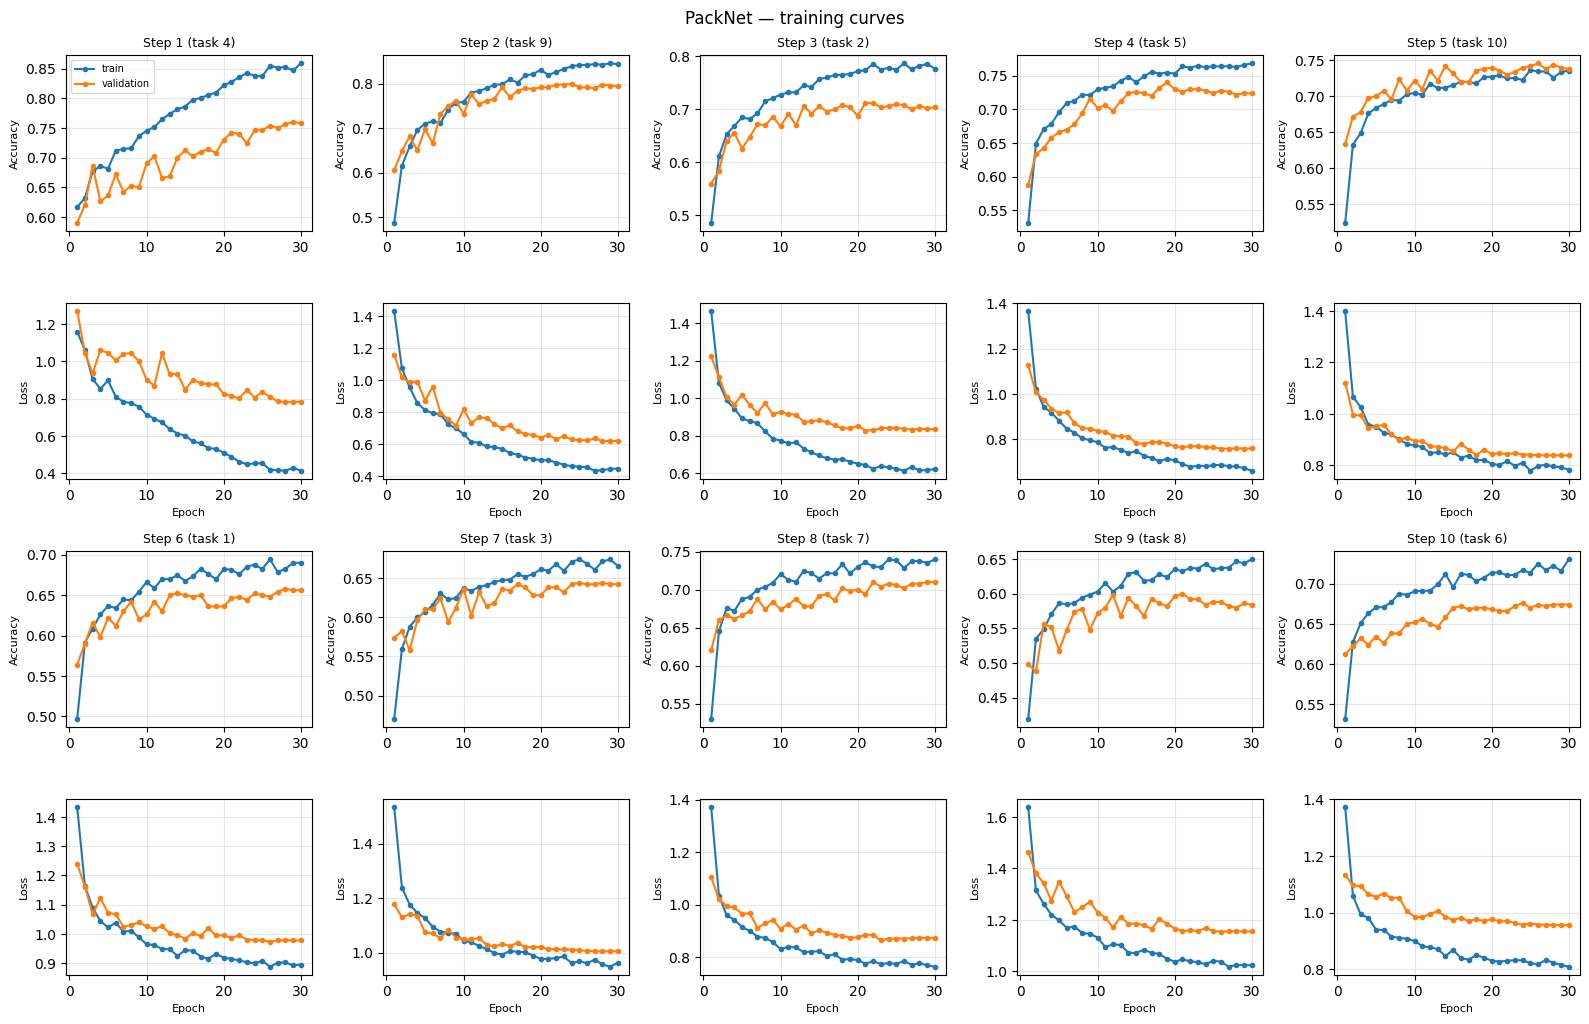

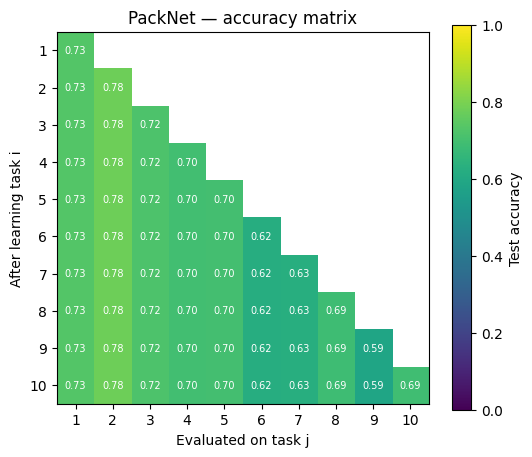

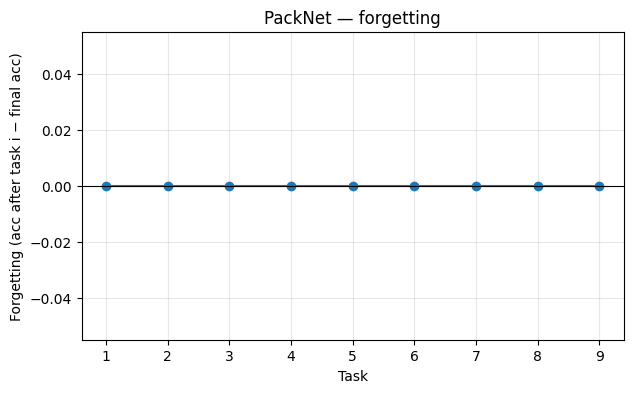

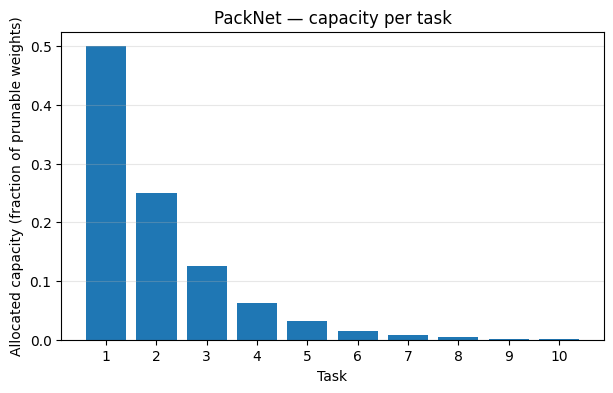

In [29]:
def plot_training_curves(histories, save_path):
    n_cols = 5
    n_blocks = math.ceil(len(histories) / n_cols)
    fig, axes = plt.subplots(2 * n_blocks, n_cols, figsize=(3.2 * n_cols, 2.6 * 2 * n_blocks), squeeze=False)
    for t, h in histories.items():
        r, c = divmod(t - 1, n_cols)
        for row, metric in ((2 * r, "accuracy"), (2 * r + 1, "loss")):
            ax = axes[row, c]
            ax.plot(h["epoch"], h[f"train_{metric}"], marker="o", ms=3, label="train")
            ax.plot(h["epoch"], h[f"validation_{metric}"], marker="o", ms=3, label="validation")
            ax.set_ylabel(metric.capitalize(), fontsize=8); ax.grid(alpha=0.3)
            if row == 2 * r:
                ax.set_title(f"Step {t} (task {ORDER[t - 1] + 1})", fontsize=9)
            else:
                ax.set_xlabel("Epoch", fontsize=8)
    axes[0, 0].legend(fontsize=7)
    for ax in axes.flat:
        if not ax.has_data():
            ax.axis("off")
    fig.suptitle("PackNet — training curves")
    fig.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_accuracy_matrix(R, save_path):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(R, vmin=0, vmax=1, cmap="viridis")
    ax.set_xlabel("Evaluated on task j"); ax.set_ylabel("After learning task i")
    ax.set_xticks(range(R.shape[1])); ax.set_yticks(range(R.shape[0]))
    ax.set_xticklabels(range(1, R.shape[1] + 1)); ax.set_yticklabels(range(1, R.shape[0] + 1))
    for i in range(R.shape[0]):
        for j in range(R.shape[1]):
            if not np.isnan(R[i, j]):
                ax.text(j, i, f"{R[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
    fig.colorbar(im, ax=ax, label="Test accuracy"); ax.set_title("PackNet — accuracy matrix")
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_forgetting(per_task, save_path):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(range(1, len(per_task) + 1), per_task, marker="o")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("Task"); ax.set_ylabel("Forgetting (acc after task i − final acc)")
    ax.set_title("PackNet — forgetting"); ax.grid(alpha=0.3)
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_capacity(per_task_alloc, save_path):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(range(1, len(per_task_alloc) + 1), per_task_alloc)
    ax.set_xticks(range(1, len(per_task_alloc) + 1))
    ax.set_xlabel("Task"); ax.set_ylabel("Allocated capacity (fraction of prunable weights)")
    ax.set_title("PackNet — capacity per task"); ax.grid(alpha=0.3, axis="y")
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


per_task_alloc = [cap["per_task_parameters"].get(t, 0) / cap["total_parameters"] for t in range(1, N_TASKS + 1)]

plot_training_curves(all_histories, PLOT_DIR / "packnet_training_curves.png")
plot_accuracy_matrix(R, PLOT_DIR / "packnet_accuracy_matrix.png")
plot_forgetting(forget["per_task"], PLOT_DIR / "packnet_forgetting.png")
plot_capacity(per_task_alloc, PLOT_DIR / "packnet_capacity.png")